In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt


import cmdstanpy
import arviz as az

import boto3
from configparser import ConfigParser
import awswrangler as wr

In [31]:
config = ConfigParser()
config.read(r'C:\Users\RyanKarel\.aws\credentials')

boto3_session = boto3.session.Session(
    aws_access_key_id=config['218527194748_ActuaryAccessProd']['aws_access_key_id'],
    aws_secret_access_key=config['218527194748_ActuaryAccessProd']['aws_secret_access_key'],
    aws_session_token=config['218527194748_ActuaryAccessProd']['aws_session_token'],
    region_name='us-east-1',
)

def query_athena(
    sql: str,
    boto3_session,
    database: str = "rn_actuary_db",
    workgroup: str = "Actuary",
    index_col = None,
    check_index_uniqueness: bool = True,
    force_index_uniqueness: bool = False,
) -> pd.DataFrame:
    output = wr.athena.read_sql_query(
        sql=sql,
        database=database,
        boto3_session=boto3_session,
        workgroup=workgroup,
        ctas_approach=False,
    )
    if index_col is not None:
        if force_index_uniqueness:
            output.drop_duplicates(subset=index_col, inplace=True)
        output.set_index(index_col, inplace=True)
        if check_index_uniqueness:
            assert output.index.is_unique
    return output

def factor_lump(s: pd.Series, options: list, other_string: str = 'Other') -> pd.Series:
    return np.where(
        s.isin(options),
        s,
        other_string
    )

def get_array(arr_string: str) -> list[list]:
    if arr_string == "[{null, null}]":
        return [[], []]
    assert arr_string.startswith('[')
    assert arr_string.endswith(']')
    s = arr_string[1:-1]
    entries = [
        [float(x) for x in increm.removeprefix('{').removesuffix('}').split(', ')]
        for increm in s.split('}, {')
    ]
    return entries

def unpack_array(arr):
    if arr == [[], []]:
        return pd.Series(index=['t', 'incurred'])
    return pd.Series(zip(*arr), index=['t', 'incurred'])

In [62]:
data = query_athena(
    sql="""
    with txns as (
        select
            num_claim,
            round(date_diff('day', dt_claim_report, timestamp_claim_transaction) / 365.0, 2) as t,
            sum(amt_incurred) as amt_incurred
        from tbl_claim_transaction ct
        inner join tbl_claim c using (num_claim)
        inner join tbl_policy p using (num_policy)
        where
            cd_financial_type = 'Loss'
            and lower(ct.cd_claim_transaction_type) not like '%recover%'
        group by 1, 2
        having sum(amt_incurred) != 0
        order by 1, 2
    ),

    settlement as (
        select
            num_claim,
            round(date_diff(
                'day',
                dt_claim_report,
                coalesce(timestamp_settlement, c.dt_claim_closed)
            ) / 365.0, 2) as t_settled,
            round(date_diff(
                'day',
                dt_claim_report,
                current_timestamp
            ) / 365.0, 2) as t_trunc
        from tbl_claim c
        left join tbl_settlement s using (num_claim)
        left join tbl_policy p using (num_policy)
        where
            coalesce(p.amt_total_attachment, 0) = 0
            and p.cd_product not in ('CP', 'IM')
            and lower(coalesce(c.cd_claim_stage, 'Other')) != 'void'
    )

    select
        num_claim,
        t_settled,
        t_trunc,
        zip(
            array_agg(t),
            array_agg(amt_incurred)
        ) as incurred_t
    from settlement
    left join txns using (num_claim)
    where
        coalesce(t_settled, 1) > 0
        -- we've known of the claim for at least some time
        and t_trunc > 0.5
    group by 1, 2, 3
    order by 1
    """,
    boto3_session=boto3_session,
    index_col='num_claim'
)
data['incurred_t'] = data['incurred_t'].map(get_array)
data[['t', 'incurred']] = data['incurred_t'].apply(unpack_array)
data['idx_claim'] = range(1, len(data) + 1)
data.sample(5)

,t_settled,t_trunc,incurred_t,t,incurred,idx_claim
num_claim,,,,,,
RN-9-0002733,0.78,1.01,"[[], []]",NaN,NaN,2171
RN-9-0000340,1.59,3.33,"[[], []]",NaN,NaN,192
RN-9-0002224,0.16,1.36,"[[], []]",NaN,NaN,1766
RN-9-0003443,NaN,0.56,"[[], []]",NaN,NaN,2767
RN-9-0000630,1.11,2.85,"[[], []]",NaN,NaN,428


In [63]:
incurred_scaler = 1e3
txns = data.explode(column=['t', 'incurred']).iloc[:, -3:].dropna()
txns['incurred'] = txns['incurred'] / incurred_scaler
txns

,t,incurred,idx_claim
num_claim,,,
RN-9-0000104,1.78,-94.58089,4
RN-9-0000104,0.27,95.0,4
RN-9-0000111,0.2,15.0,10
RN-9-0000120,0.96,0.1,16
RN-9-0000121,1.68,15.0,17
...,...,...,...
RN-9-0003520,0.02,282.25,2837
RN-9-0003524,0.14,90.0,2841
RN-9-0003525,0.39,-5.8,2842


In [324]:
homog_mpp = cmdstanpy.CmdStanModel(stan_file=r'..\models\marked-point-process\incurred__homogeneous_poisson__certain_domain__uncensored.stan')
piecewise_mpp = cmdstanpy.CmdStanModel(stan_file=r'..\models\marked-point-process\incurred__piecewise_with_settlement__uncensored.stan')
reserve_mpp = cmdstanpy.CmdStanModel(stan_file=r'..\models\marked-point-process\incurred__reserve_state_frailty__uncensored.stan')

17:04:14 - cmdstanpy - INFO - compiling stan file C:\Users\RYANKA~1\AGGREG~1\models\MARKED~1\incurred__piecewise_with_settlement__uncensored.stan to exe file C:\Users\RyanKarel\Aggregate Loss Cost Modeling\models\marked-point-process\incurred__piecewise_with_settlement__uncensored.exe
17:06:13 - cmdstanpy - INFO - compiled model executable: C:\Users\RyanKarel\Aggregate Loss Cost Modeling\models\marked-point-process\incurred__piecewise_with_settlement__uncensored.exe


### Matched cross-validation: homogeneous, settlement, and reserve-state models

All three models use the same seeded three-fold claim splits, observed horizons, mark units, scoring grid, and score draw limit. Each model is refit in every fold; no posterior is reused across models. Settlement times for held-out paths are simulated, not supplied as known outcomes. The settlement model has constant intensity while open and zero afterward.

The reserve-state model (`incurred__reserve_state_frailty__uncensored.stan`) sorts each claim's transactions by time and tracks its cumulative reserve. From zero, the next transaction is a positive lognormal reserve. While reserved, a transaction closes the reserve to exactly zero with logit probability linear in log reserve, or moves it to `log(L_new) = log(L) + a + b * z + Laplace error`, where `z` is the centered log reserve and `b < 0` gives mean reversion. Simulated paths therefore stay non-negative and do not compound explosively. Intensity is `frailty * exp(log_lambda[state] - beta[state] * age)` until a Weibull settlement time, with gamma claim frailty integrated out of the likelihood. It rejects data whose cumulative incurred goes negative, with a negative transaction from zero, or with zero settlement times.

`model_comparison` reports paired differences as candidate minus homogeneous for each candidate: negative means better for the candidate. Missing variogram scores are excluded from both differences and win fractions. PIT tests are reported separately by model; they are approximate and their Holm adjustment is within each model's evaluation ages. Predictions from different folds are not joint portfolio posterior draws.

Claims with transactions after recorded settlement are explicitly excluded from ALL models, including all their transactions. `settlement_exclusions` reports the excluded claims and offending transaction counts. Other invalid times still raise errors. Original `data` and `txns` are preserved; fitting and scoring use `comparison_data` and `comparison_txns`. Results apply to this restricted population, not claims with post-settlement development. This cell sequence reruns every model's CV fits, which may take substantial time.

In [325]:
from sklearn.model_selection import KFold

def data_preprocessing(
        claims_data: pd.DataFrame,
        transactions: pd.DataFrame
    ) -> dict:
    if claims_data.empty or not claims_data.index.is_unique:
        raise ValueError('claims_data must have a nonempty, unique claim index.')
    claim_positions = claims_data.index.get_indexer(transactions.index)
    if (claim_positions < 0).any():
        raise ValueError('Every transaction must belong to a claim in claims_data.')
    stan_data = {
        'C': len(claims_data),
        'N': len(transactions),
        't_settled': claims_data['t_settled'].fillna(-1),
        't_trunc': claims_data['t_trunc'],
        'idx_claim': claim_positions + 1,
        't': transactions['t'],
        'x_t': transactions['incurred'],
        'posterior_predictive_grain': 0.1,
        'C_out': 0,
        't_settled_out': [],
        't_trunc_out': []
    }
    return stan_data

def fit(
        model: cmdstanpy.CmdStanModel,
        stan_data: dict,
        sample_kw: dict = None
    ) -> cmdstanpy.CmdStanMCMC:
    mcmc = model.sample(
        data=stan_data,
        **(sample_kw or {})
    )
    return mcmc

def fit_predict(
        model: cmdstanpy.CmdStanModel,
        claims_data: pd.DataFrame,
        transactions: pd.DataFrame,
        sample_kw: dict = None
    ) -> np.ndarray:
    """Return in-sample predictive paths with axes (draw, claim, time bin)."""
    stan_data = data_preprocessing(claims_data, transactions)
    stan_data.update({
        'C_out': len(claims_data),
        't_settled_out': stan_data['t_settled'],
        't_trunc_out': stan_data['t_trunc']
    })
    mcmc = fit(
        model=model,
        stan_data=stan_data,
        sample_kw=sample_kw
    )
    return mcmc.stan_variable('X')

def cross_val_predict(
        model: cmdstanpy.CmdStanModel,
        claims_data: pd.DataFrame,
        transactions: pd.DataFrame,
        cv: int = 5,
        sample_kw: dict = None,
        random_state: int | None = None,
        dtype=np.float64
    ) -> np.ndarray:
    """Return out-of-fold paths in original claim order: (draw, claim, time bin).

    Paths stay flat after each claim's horizon. Draw indices across folds
    do not represent a shared posterior parameter draw. Folds are written into
    one preallocated array of ``dtype`` to avoid a second full-size copy.
    """
    # not storing results, but running some checks on the indices of the two data frames
    data_preprocessing(claims_data, transactions)
    claim_population = claims_data.index

    X = None
    k_fold = KFold(n_splits=cv, shuffle=True, random_state=random_state)
    for train_index, test_index in k_fold.split(claim_population):
        claim_subset_train = claim_population[train_index]
        claim_subset_test = claim_population[test_index]

        stan_training_data = data_preprocessing(
            claims_data=claims_data.loc[claim_subset_train],
            transactions=transactions.loc[transactions.index.isin(claim_subset_train)]
        )
        mcmc_train = fit(
            model=model,
            stan_data=stan_training_data,
            sample_kw=sample_kw
        )
        prediction_data = {
            **stan_training_data,
            "C_out": len(claim_subset_test),
            "t_settled_out": claims_data.loc[claim_subset_test, 't_settled'].fillna(-1),
            "t_trunc_out": claims_data.loc[claim_subset_test, 't_trunc']
        }

        gq = model.generate_quantities(
            data=prediction_data,
            previous_fit=mcmc_train,
            seed=random_state
        )

        X_i = gq.stan_variable("X")
        del gq
        if X is None:
            projection_width = int(np.ceil(
                claims_data['t_trunc'].max() / stan_training_data['posterior_predictive_grain']
            ))
            X = np.empty(
                (X_i.shape[0], len(claim_population), max(projection_width, X_i.shape[2])),
                dtype=dtype
            )
        if X_i.shape[0] != X.shape[0] or X_i.shape[2] > X.shape[2]:
            raise ValueError(
                f'Fold output shape {X_i.shape} is incompatible with combined shape {X.shape}.'
            )
        fold_width = X_i.shape[2]
        X[:, test_index, :fold_width] = X_i
        # Paths stay flat after the fold's horizon; empty folds are all zero.
        X[:, test_index, fold_width:] = X_i[:, :, -1:] if fold_width > 0 else 0
        del X_i
    return X

In [327]:
data_preprocessing(data, txns)
settlement_times = data['t_settled'].fillna(-1)
invalid_settlement = (settlement_times != -1) & (
    (settlement_times < 0) | (settlement_times > data['t_trunc'])
)
transaction_times = txns['t'].to_numpy(dtype=float)
transaction_horizons = data['t_trunc'].reindex(txns.index).to_numpy(dtype=float)
invalid_transactions = (
    ~np.isfinite(transaction_horizons)
    | (transaction_times < 0)
    | ~np.isfinite(transaction_times)
    | (transaction_times > transaction_horizons)
    | (transaction_horizons == 0)
)
if (invalid_settlement.any() or invalid_transactions.any()
        or not np.isfinite(data['t_trunc'].to_numpy(dtype=float)).all()
        or (data['t_trunc'] < 0).any()):
    raise ValueError(
        f'Settlement model incompatible with {invalid_settlement.sum()} claim settlement times '
        f'and {invalid_transactions.sum()} transaction times. '
        'Review invalid settlement/evaluation times or transactions outside evaluation horizons.'
    )

transaction_settlements = settlement_times.reindex(txns.index).to_numpy(dtype=float)
post_settlement = (transaction_settlements != -1) & (transaction_times > transaction_settlements)
excluded_counts = txns.loc[post_settlement].groupby(level=0).size()
settlement_exclusions = data.loc[data.index.isin(excluded_counts.index), ['t_settled', 't_trunc']].copy()
settlement_exclusions['n_post_settlement_transactions'] = excluded_counts
comparison_data = data.loc[~data.index.isin(excluded_counts.index)].copy()
comparison_txns = txns.loc[txns.index.isin(comparison_data.index)].copy()
print(
    f'Excluded {len(settlement_exclusions)} claims with {post_settlement.sum()} '
    f'post-settlement transactions; removed {len(txns) - len(comparison_txns)} '
    f'total transactions. Retained {len(comparison_data)} claims for both models.'
)
display(settlement_exclusions)
if ((settlement_times == 0) & data.index.isin(comparison_txns.index)).any():
    raise ValueError('Transactions at zero settlement time have zero open exposure.')
if len(comparison_data) < 3:
    raise ValueError('At least three compatible claims are required for three-fold CV.')
if (comparison_data['t_settled'] == 0).any():
    raise ValueError('The reserve-state model requires positive settlement times (Weibull density).')

# float32 keeps three full out-of-fold path arrays in memory at once.
cv_options = dict(cv=3, random_state=42, sample_kw={'seed': 42}, dtype=np.float32)
homog_output = cross_val_predict(homog_mpp, comparison_data, comparison_txns, **cv_options)
piecewise_output = cross_val_predict(piecewise_mpp, comparison_data, comparison_txns, **cv_options)
reserve_output = cross_val_predict(reserve_mpp, comparison_data, comparison_txns, **cv_options)
output = homog_output  # Keep the existing single-model path plot working.

Excluded 17 claims with 26 post-settlement transactions; removed 69 total transactions. Retained 2867 claims for both models.


,t_settled,t_trunc,n_post_settlement_transactions
num_claim,,,
RN-9-0000158,2.55,3.77,2
RN-9-0000188,0.82,3.68,1
RN-9-0000427,0.35,3.18,2
RN-9-0000432,1.80,3.18,3
RN-9-0000565,1.13,2.97,2
RN-9-0000783,2.41,2.64,1
RN-9-0000854,0.99,2.56,2
RN-9-0000884,1.10,2.53,1
RN-9-0000958,1.22,2.45,1


17:10:46 - cmdstanpy - INFO - CmdStan start processing


chain 1:   0%|          | 0/2000 [00:00<?, ?it/s, (Warmup)]

chain 2:   0%|          | 0/2000 [00:00<?, ?it/s, (Warmup)]

...

chain 2:   0%|          | 0/2000 [00:00<?, ?it/s, (Warmup)]

chain 3:   0%|          | 0/2000 [00:00<?, ?it/s, (Warmup)]

chain 4:   0%|          | 0/2000 [00:00<?, ?it/s, (Warmup)]

17:15:36 - cmdstanpy - INFO - CmdStan done processing.
17:15:36 - cmdstanpy - WARNING - Non-fatal error during sampling:
Exception: Exception: pareto_type_2_lpdf: Scale parameter[1] is inf, but must be positive finite! (in 'incurred__piecewise_with_settlement__uncensored.stan', line 59, column 8 to column 63) (in 'incurred__piecewise_with_settlement__uncensored.stan', line 173, column 4 to line 180, column 6)
	Exception: Exception: pareto_type_2_lpdf: Scale parameter[1] is inf, but must be positive finite! (in 'incurred__piecewise_with_settlement__uncensored.stan', line 59, column 8 to column 63) (in 'incurred__piecewise_with_settlement__uncensored.stan', line 173, column 4 to line 180, column 6)
	Exception: exponential_lpdf: Inverse scale parameter is inf, but must be positive finite! (in 'incurred__piecewise_with_settlement__uncensored.stan', line 159, column 12 to column 71)
	Exception: exponential_lpdf: Inverse scale parameter is inf, but must be positive finite! (in 'incurred__pie

17:15:58 - cmdstanpy - INFO - Chain [3] done processing
17:15:58 - cmdstanpy - INFO - Chain [2] done processing
17:15:58 - cmdstanpy - INFO - Chain [1] done processing
17:15:58 - cmdstanpy - INFO - Chain [4] done processing


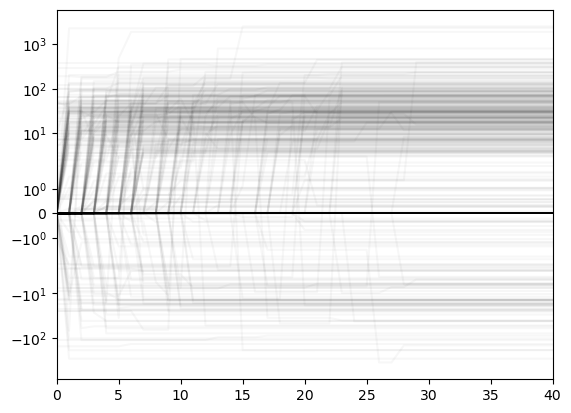

In [329]:
from random import choice
integer_sample = choice(range(output.shape[1]))

ax = plt.plot(piecewise_output[:1000, integer_sample, :].T, alpha=0.03, color='k')
plt.yscale("symlog")
plt.xlim(0, 40)
plt.show()

### Out-of-fold path scores by claim

Lower is better. Observed cumulative incurred is binned using the same right-endpoint convention as Stan (time zero goes in the first bin). Only bins through each claim's own `t_trunc` are scored, including its last partial bin; flat padding is excluded. Values remain in the scaled incurred units used by `txns`.

Energy score: mean Euclidean distance to the observed path minus half the mean distance between independent draws from the empirical predictive distribution (including diagonal pairs). Variogram score: the mean squared discrepancy in expected absolute time-pair differences raised to power `p=0.5`, with equal weights over unordered distinct pairs. This is the usual equal-weight variogram sum divided by the number of pairs. Claims with fewer than two bins have no variogram score; zero-horizon claims have neither score.

For runtime, the default uses a reproducible random subset of at most 200 posterior predictive draws, shared across claims. Set `max_draws=None` to use all draws (energy computation is quadratic in draw count). Scores are exact for the selected empirical ensemble, not unbiased estimates of scores for the full posterior. Different claim horizons have different dimensions, so compare models on the same claims/grid rather than interpreting cross-claim score differences as calibration alone.

Fixed-age diagnostics use **all** predictive draws, before score subsampling. For each requested positive grid endpoint, `actual_t...`, `prediction_mean_t...`, and `actual_percentile_t...` are missing unless `t_trunc >= endpoint`. Percentiles are on a 0-100 scale and use a continuous randomized ensemble rank: `100 * (L + U * (E + 1)) / (M + 1)`, where L counts draws strictly below the actual, E counts ties, M is the ensemble size, and U is an independent uniform draw. Including the observation among ties handles both point masses and finite-ensemble rank uncertainty. Divide by 100 for a PIT-like value on [0, 1]. Under exchangeable calibrated observations and predictive simulations, these values are uniform marginally; correlated MCMC draws and overlapping CV training sets make this reference approximate. Randomization is reproducible via `random_state` and independent of score subsampling.

In [330]:
from scipy.spatial.distance import pdist

def _validate_path_score_inputs(
        predictions: np.ndarray,
        claims_data: pd.DataFrame,
        grain: float,
        p: float,
        max_draws: int | None
    ) -> tuple[np.ndarray, np.ndarray, np.ndarray]:
    """Validate ensemble shape and scoring options; return draws, horizons, widths."""
    predictions = np.asarray(predictions)
    if predictions.ndim != 3 or predictions.shape[0] == 0:
        raise ValueError('predictions must have shape (nonzero draws, claims, bins).')
    if predictions.shape[1] != len(claims_data) or not claims_data.index.is_unique:
        raise ValueError('Prediction claims must match a unique claims_data index in row order.')
    if not np.isfinite(grain) or grain <= 0 or not np.isfinite(p) or not 0 < p < 2:
        raise ValueError('grain must be positive and finite; p must be finite and in (0, 2).')
    if max_draws is not None and (not isinstance(max_draws, int) or max_draws < 1):
        raise ValueError('max_draws must be a positive integer or None.')
    horizons = claims_data['t_trunc'].to_numpy(dtype=float)
    if not np.isfinite(horizons).all() or (horizons < 0).any():
        raise ValueError('Claim horizons must be finite and nonnegative.')
    widths_float = np.ceil(horizons / grain)
    if (widths_float > predictions.shape[2]).any():
        raise ValueError('Predictions do not cover every claim horizon at this grain.')
    widths = widths_float.astype(int)
    return predictions, horizons, widths

def _observed_cumulative_paths(
        claims_data: pd.DataFrame,
        transactions: pd.DataFrame,
        horizons: np.ndarray,
        widths: np.ndarray,
        grain: float,
        projection_width: int
    ) -> np.ndarray:
    """Bin valid transactions like Stan, including time zero in the first bin.

    Return cumulative paths in claim row order, flat-padded to projection_width.
    """
    claim_positions = claims_data.index.get_indexer(transactions.index)
    if (claim_positions < 0).any():
        raise ValueError('Every transaction must belong to claims_data.')
    times = transactions['t'].to_numpy(dtype=float)
    amounts = transactions['incurred'].to_numpy(dtype=float)
    if not np.isfinite(times).all() or not np.isfinite(amounts).all():
        raise ValueError('Transaction times and incurred values must be finite.')
    if ((times < 0) | (times > horizons[claim_positions])).any():
        raise ValueError('Transaction times must be within their claim horizons.')
    if (widths[claim_positions] == 0).any():
        raise ValueError('Zero-horizon claims cannot contain transactions for this model.')

    observed = np.zeros((len(claims_data), projection_width))
    bins = np.maximum(1, np.ceil(times / grain).astype(int)) - 1
    np.add.at(observed, (claim_positions, bins), amounts)
    return np.cumsum(observed, axis=1)

def _randomized_rank_percentiles(
        ensemble: np.ndarray,
        actual: np.ndarray,
        rng: np.random.Generator
    ) -> np.ndarray:
    """Return 0-100 randomized ensemble ranks, including the actual among ties.

    Columns are claims; (L + U * (E + 1)) / (M + 1) handles finite draws and atoms.
    """
    below = (ensemble < actual).sum(axis=0)
    tied = (ensemble == actual).sum(axis=0)
    return 100 * (
        below + rng.random(ensemble.shape[1]) * (tied + 1)
    ) / (ensemble.shape[0] + 1)

def _fixed_age_diagnostics(
        predictions: np.ndarray,
        observed: np.ndarray,
        claim_index: pd.Index,
        horizons: np.ndarray,
        grain: float,
        evaluation_times: tuple[float, ...],
        random_state: int
    ) -> pd.DataFrame:
    """Use all draws for actuals, means and randomized ranks at valid grid ages.

    Claims not yet observed at an age receive NaN for all three diagnostics.
    """
    evaluation_times = np.asarray(evaluation_times, dtype=float)
    if evaluation_times.ndim != 1 or not np.isfinite(evaluation_times).all():
        raise ValueError('evaluation_times must be a finite one-dimensional sequence.')
    endpoints = np.rint(evaluation_times / grain)
    if (evaluation_times <= 0).any() or not np.allclose(
            evaluation_times / grain, endpoints, rtol=0, atol=1e-8):
        raise ValueError('evaluation_times must be positive endpoints of the discretized grid.')
    labels = [repr(float(time)) for time in evaluation_times]
    if len(set(labels)) != len(labels):
        raise ValueError('evaluation_times must be unique.')
    diagnostics = pd.DataFrame(index=claim_index)
    pit_rng = np.random.default_rng(random_state)
    for time, endpoint, label in zip(evaluation_times, endpoints, labels):
        eligible = horizons >= time
        actual = np.full(len(claim_index), np.nan)
        prediction_mean = np.full(len(claim_index), np.nan)
        percentile = np.full(len(claim_index), np.nan)
        if eligible.any():
            bin_index = int(endpoint) - 1
            if bin_index < 0 or bin_index >= predictions.shape[2]:
                raise ValueError(f'Predictions do not cover evaluation time {time}.')
            ensemble = predictions[:, eligible, bin_index]
            if not np.isfinite(ensemble).all():
                raise ValueError(f'Nonfinite predictions at evaluation time {time}.')
            actual[eligible] = observed[eligible, bin_index]
            prediction_mean[eligible] = ensemble.mean(axis=0)
            percentile[eligible] = _randomized_rank_percentiles(
                ensemble, actual[eligible], pit_rng
            )
        diagnostics[f'actual_t{label}'] = actual
        diagnostics[f'prediction_mean_t{label}'] = prediction_mean
        diagnostics[f'actual_percentile_t{label}'] = percentile
    return diagnostics

def _select_score_draws(
        predictions: np.ndarray,
        max_draws: int | None,
        random_state: int
    ) -> np.ndarray:
    """Select a reproducible common draw subset without consuming the PIT RNG."""
    if max_draws is not None and predictions.shape[0] > max_draws:
        selected = np.random.default_rng(random_state).choice(
            predictions.shape[0], max_draws, replace=False
        )
        predictions = predictions[selected]
    return predictions

def _energy_score(ensemble: np.ndarray, truth: np.ndarray) -> float:
    """Empirical energy score with Euclidean norm and diagonal-inclusive pairs."""
    return (
        np.linalg.norm(ensemble - truth, axis=1).mean()
        - pdist(ensemble, metric='euclidean').sum() / ensemble.shape[0]**2
    )

def _variogram_score(ensemble: np.ndarray, truth: np.ndarray, p: float) -> float:
    """Average order-p variogram discrepancy over unordered time pairs.

    Return NaN for fewer than two bins; process by lag to avoid a draw-by-bin-pair array.
    """
    width = truth.size
    if width < 2:
        return np.nan
    squared_error = 0.0
    for lag in range(1, width):
        predicted_difference = np.mean(
            np.abs(ensemble[:, lag:] - ensemble[:, :-lag])**p, axis=0
        )
        observed_difference = np.abs(truth[lag:] - truth[:-lag])**p
        squared_error += np.sum((observed_difference - predicted_difference)**2)
    return squared_error / (width * (width - 1) / 2)

def _path_score_table(
        predictions: np.ndarray,
        observed: np.ndarray,
        widths: np.ndarray,
        claim_index: pd.Index,
        p: float
    ) -> pd.DataFrame:
    """Score each claim through its own horizon, excluding flat padding."""
    n_draws = predictions.shape[0]
    energy = np.full(len(claim_index), np.nan)
    variogram = np.full(len(claim_index), np.nan)
    for c, width in enumerate(widths):
        if width == 0:
            continue
        ensemble = predictions[:, c, :width]
        if not np.isfinite(ensemble).all():
            raise ValueError(f'Nonfinite predictions for claim {claim_index[c]!r}.')
        truth = observed[c, :width]
        energy[c] = _energy_score(ensemble, truth)
        variogram[c] = _variogram_score(ensemble, truth, p)
    return pd.DataFrame({
        'energy_score': energy,
        'variogram_score': variogram,
        'n_time_bins': widths,
        'n_predictive_draws': n_draws
    }, index=claim_index)

def claim_path_scores(
        predictions: np.ndarray,
        claims_data: pd.DataFrame,
        transactions: pd.DataFrame,
        grain: float,
        p: float = 0.5,
        max_draws: int | None = 200,
        random_state: int = 42,
        evaluation_times: tuple[float, ...] = (1.0, 2.0, 3.0)
    ) -> pd.DataFrame:
    """Return claim-indexed out-of-fold path scores and fixed-age diagnostics.

    predictions has axes (draw, claim, time bin), in claims_data row order.
    transactions uses claim labels as its index and the same incurred units.
    grain must match prediction binning; evaluation_times are positive grid endpoints.
    Path scores use at most max_draws (None means all); age diagnostics always use all.
    random_state reproducibly controls separate rank and draw-selection generators.
    Zero-horizon scores and ages beyond a claim's horizon are NaN.
    """
    predictions, horizons, widths = _validate_path_score_inputs(
        predictions, claims_data, grain, p, max_draws
    )
    observed = _observed_cumulative_paths(
        claims_data, transactions, horizons, widths, grain, predictions.shape[2]
    )
    diagnostics = _fixed_age_diagnostics(
        predictions, observed, claims_data.index, horizons,
        grain, evaluation_times, random_state
    )
    score_draws = _select_score_draws(predictions, max_draws, random_state)
    scores = _path_score_table(score_draws, observed, widths, claims_data.index, p)
    return scores.join(diagnostics)


In [331]:
score_options = dict(
    claims_data=comparison_data,
    transactions=comparison_txns,
    grain=data_preprocessing(comparison_data, comparison_txns)['posterior_predictive_grain'],
    max_draws=200,
    random_state=42,
    evaluation_times=(1.0, 2.0, 3.0)
)
homog_claim_scores = claim_path_scores(predictions=homog_output, **score_options)
piecewise_claim_scores = claim_path_scores(predictions=piecewise_output, **score_options)
reserve_claim_scores = claim_path_scores(predictions=reserve_output, **score_options)
claim_scores = homog_claim_scores
score_columns = ['energy_score', 'variogram_score']
model_scores = {
    'Homogeneous': homog_claim_scores,
    'Settlement': piecewise_claim_scores,
    'Reserve state': reserve_claim_scores,
}

def compare_to_baseline(candidate_scores, baseline_scores, columns=score_columns):
    """Paired candidate-minus-baseline score summary; negative favors the candidate."""
    differences = candidate_scores[columns] - baseline_scores[columns]
    return pd.DataFrame({
        'baseline_mean': baseline_scores[columns].mean(),
        'candidate_mean': candidate_scores[columns].mean(),
        'mean_difference': differences.mean(),
        'median_difference': differences.median(),
        'fraction_claims_candidate_better': differences.lt(0).where(differences.notna()).mean(),
        'n_paired_claims': differences.count(),
    })

model_comparison = pd.concat(
    {
        name: compare_to_baseline(scores, homog_claim_scores)
        for name, scores in model_scores.items()
        if name != 'Homogeneous'
    },
    names=['candidate_vs_homogeneous', 'score'],
)
model_comparison

,homog_mean,piecewise_mean,mean_difference_piecewise_minus_homog,median_difference,fraction_claims_piecewise_better,n_paired_claims
energy_score,52.453266,52.533481,0.080214,0.820718,0.354726,2867
variogram_score,5.400954,5.337191,-0.063763,-0.013421,0.507848,2867


### Predictive score and calibration summary

Score histograms use log x-axes and logarithmically spaced bins for positive scores. Zero scores cannot be plotted on a log axis and are counted explicitly on each panel; arithmetic means include zeros. No tail trimming is applied. Percentile histograms use common 0-100 bins and density scaling so ages with different eligible claim counts are comparable. The dashed line is the uniform density, 0.01.

Two-sided one-sample Kolmogorov-Smirnov tests compare each age's randomized percentiles to Uniform(0, 100). Holm adjustment controls multiple testing across the nonempty ages under valid individual p-values. Here p-values are **approximate diagnostics**: claims share CV fits, may have other dependence, and simulations use correlated posterior draws. Failure to reject is not evidence that the full path distribution is correct.

In [332]:
from scipy.stats import kstest

def plot_claim_score_summary(
        claim_scores: pd.DataFrame,
        bins: int = 20,
        significance: float = 0.05
    ) -> tuple[plt.Figure, np.ndarray, pd.DataFrame]:
    """Plot score distributions and age-specific randomized percentile calibration.

    Discover ages from actual_percentile_t... columns (0-100 scale).
    Return figure, three axes, and KS results including Holm-adjusted p-values.
    Missing values are excluded separately by column; infinities are rejected.
    Tests assume independent calibrated ranks, so shared CV fits make them approximate.
    """
    if not isinstance(bins, int) or bins < 1:
        raise ValueError('bins must be a positive integer.')
    if not np.isfinite(significance) or not 0 < significance < 1:
        raise ValueError('significance must be in (0, 1).')
    if not claim_scores.columns.is_unique:
        raise ValueError('claim_scores must have unique column names.')
    score_columns = ['energy_score', 'variogram_score']
    missing = set(score_columns) - set(claim_scores.columns)
    if missing:
        raise ValueError(f'Missing score columns: {sorted(missing)}')
    prefix = 'actual_percentile_t'
    percentile_columns = [
        column for column in claim_scores.columns
        if isinstance(column, str) and column.startswith(prefix)
    ]
    if not percentile_columns:
        raise ValueError('No actual_percentile_t... columns found.')
    ages = {column: float(column[len(prefix):]) for column in percentile_columns}
    if not all(np.isfinite(age) and age > 0 for age in ages.values()):
        raise ValueError('Percentile column ages must be positive and finite.')
    percentile_columns.sort(key=ages.get)
    values = {}
    for column in score_columns + percentile_columns:
        sample = claim_scores[column].dropna().to_numpy(dtype=float)
        if not np.isfinite(sample).all():
            raise ValueError(f'Nonfinite values in {column}.')
        if column in score_columns and (sample < 0).any():
            raise ValueError(f'Negative scores in {column} cannot be shown on a log axis.')
        if column in percentile_columns and ((sample < 0) | (sample > 100)).any():
            raise ValueError(f'Percentiles in {column} must be in [0, 100].')
        values[column] = sample

    records = []
    for column in percentile_columns:
        sample = values[column]
        statistic, p_value = kstest(sample / 100, 'uniform') if sample.size else (np.nan, np.nan)
        records.append({
            'evaluation_time': ages[column], 'n_claims': sample.size,
            'ks_statistic': statistic, 'p_value': p_value
        })
    tests = pd.DataFrame(records).set_index('evaluation_time')
    tests['p_value_holm'] = np.nan
    valid = tests['p_value'].dropna().sort_values()
    adjusted = np.minimum(1, np.maximum.accumulate(
        valid.to_numpy() * np.arange(len(valid), 0, -1)
    ))
    tests.loc[valid.index, 'p_value_holm'] = adjusted
    tests['assessment'] = [
        'No eligible claims' if pd.isna(value) else
        ('Reject uniformity' if value < significance else 'Uniformity not rejected')
        for value in tests['p_value_holm']
    ]

    fig, axes = plt.subplots(1, 3, figsize=(18, 5))
    for ax, column, title in zip(axes[:2], score_columns, ['Energy score', 'Variogram score']):
        sample = values[column]
        ax.set_xscale('log')
        if sample.size:
            mean = sample.mean()
            positive = sample[sample > 0]
            if positive.size:
                lower, upper = positive.min(), positive.max()
                if lower == upper:
                    lower, upper = lower / 2, upper * 2
                score_edges = np.geomspace(lower, upper, bins + 1)
                ax.hist(positive, bins=score_edges, alpha=0.75,
                        color='steelblue', edgecolor='white')
                ax.axvline(mean, color='darkred', linestyle='--', label=f'Mean = {mean:.6g}')
                ax.legend()
            else:
                ax.text(0.5, 0.5, 'All scores are zero; mean = 0',
                        ha='center', va='center', transform=ax.transAxes)
            ax.text(0.02, 0.98, f'Zero scores (not plotted): {np.count_nonzero(sample == 0)}',
                    ha='left', va='top', transform=ax.transAxes)
        else:
            ax.text(0.5, 0.5, 'No eligible claims; mean unavailable',
                    ha='center', va='center', transform=ax.transAxes)
        ax.set(title=f'{title} (n={sample.size})', xlabel=title, ylabel='Claim count')
    edges = np.linspace(0, 100, bins + 1)
    colors = plt.get_cmap('tab10')
    for i, column in enumerate(percentile_columns):
        sample = values[column]
        if sample.size:
            age = ages[column]
            row = tests.loc[age]
            axes[2].hist(
                sample, bins=edges, density=True, alpha=0.35,
                color=colors(i % 10),
                label=f't={age:g}, n={sample.size}, Holm p={row.p_value_holm:.3g}'
            )
    axes[2].axhline(0.01, color='black', linestyle='--', label='Uniform density')
    axes[2].set(xlim=(0, 100), xlabel='Randomized percentile', ylabel='Density',
                title=f'Approximate uniformity checks (Holm alpha={significance:g})')
    axes[2].legend(fontsize='small')
    fig.tight_layout()
    return fig, axes, tests


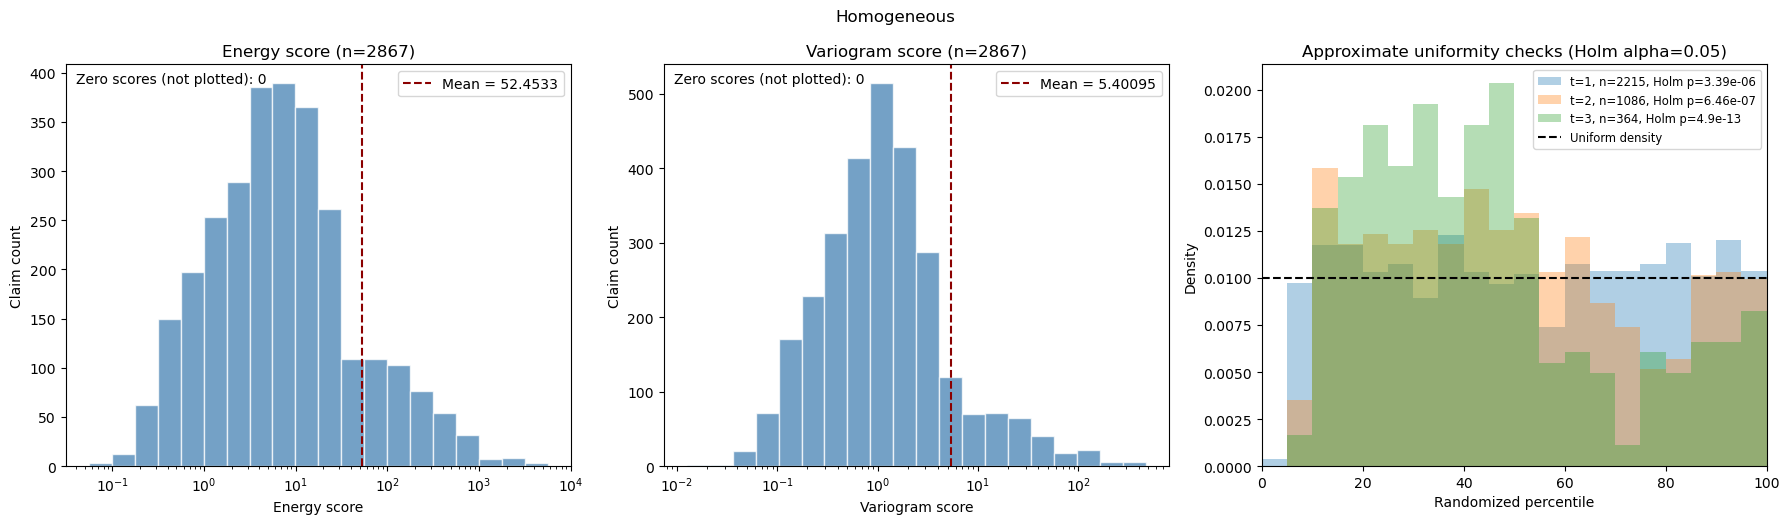

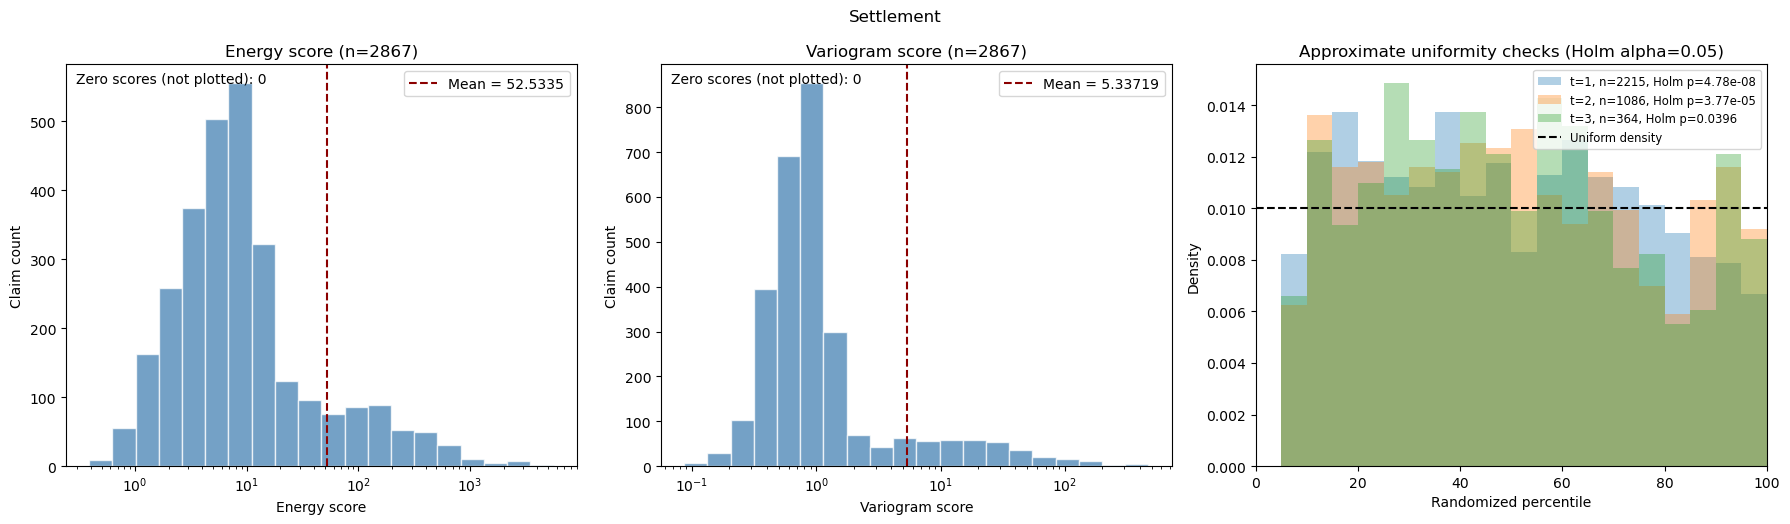

n_claims  ks_statistic       p_value  \
model       evaluation_time                                         
Homogeneous 1.0                  2215      0.054675  3.394270e-06   
            2.0                  1086      0.084643  3.228300e-07   
            3.0                   364      0.202125  1.633712e-13   
Settlement  1.0                  2215      0.064778  1.593212e-08   
            2.0                  1086      0.072806  1.883430e-05   
            3.0                   364      0.072923  3.959515e-02   

                             p_value_holm         assessment  
model       evaluation_time                                   
Homogeneous 1.0              3.394270e-06  Reject uniformity  
            2.0              6.456601e-07  Reject uniformity  
            3.0              4.901137e-13  Reject uniformity  
Settlement  1.0              4.779635e-08  Reject uniformity  
            2.0              3.766859e-05  Reject uniformity  
            3.0              3.959515e-02  Reject uniformity

In [333]:
uniformity_results = {}
for name, scores in model_scores.items():
    figure, axes, tests = plot_claim_score_summary(scores)
    figure.suptitle(name, y=1.04)
    plt.show()
    uniformity_results[name] = tests
percentile_uniformity_tests = pd.concat(uniformity_results, names=['model'])
percentile_uniformity_tests